# Власний проєкт донавчання: Text-to-SQL генерація з LoRA SFT
**Виконав:** студент групи ВТ-23-1 Горбачов Олег

У цьому ноутбуці виконуємо повний цикл донавчання (Supervised Fine-Tuning з **LoRA**) компактної відкритої мовної моделі **`Qwen/Qwen3-0.6B`** для прикладної задачі **Text-to-SQL**: перетворення запиту природною мовою разом із DDL-схемою таблиць (`CREATE TABLE ...`) у чистий, виконуваний SQL-запит.

---

## 1.1. Задача та обґрунтування потреби донавчання

### Чому обрано Text-to-SQL на компактній моделі (`0.6B`)
- **Практичне застосування:** локальні або корпоративні аналітичні помічники часто потребують швидкої генерації SQL на власному обладнанні (без передачі схем БД та запитів у зовнішні API).
- **Чому не вистачає zero-shot промптингу:** компактна модель (`0.6B`) «із коробки» схильна:
  1. Порушувати суворий формат відповіді — додавати пояснення природною мовою або markdown-блоки `` ```sql ... ``` ``.
  2. Галюцинувати назви колонок і таблиць, яких немає у `CREATE TABLE` (особливо при кількаразових умовах або `JOIN`).
  3. Плутати агрегації (`COUNT`, `MAX`, `AVG`) та умови групування `GROUP BY` / `HAVING`.
- **Чому few-shot prompting і RAG не розв'язують задачу оптимально:**
  - Додавання 5–10 прикладів `CREATE TABLE -> SQL` у контекст збільшує довжину кожного запиту на `500–1000` токенів (додаткові витрати пам'яті, затримки та вартості на кожен виклик), але на `0.6B` моделі все одно не гарантує 100% форматної та синтаксичної чистоти.
  - **RAG** тут не потрібен для знання схеми, оскільки релевантна DDL-схема **вже передається у запиті**; проблема полягає не у браку фактів, а у **поведінці суворого SQL-транслятора** та дотриманні формату.
- **Чому SFT + LoRA оптимальні:** SFT навчає модель поводитися як детермінований SQL-генератор із коротким системним промптом (~25 токенів), не втрачаючи загального розуміння мови й вимагаючи лише ~1.6% тренованих параметрів.


In [1]:
import gc
import os
import re
import sqlite3
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

set_seed(42)

assert torch.cuda.is_available(), "Потрібна GPU з CUDA"
print(f"Пристрій: {torch.cuda.get_device_name(0)}")
print(f"Загальна VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Пристрій: NVIDIA GeForce GTX 1070
Загальна VRAM: 8.59 GB


## 1.2. Модель, дані та розбиття без витоку (`b-mc2/sql-create-context`)

Використовуємо датасет **`b-mc2/sql-create-context`** (78 577 пар «DDL-схема + питання → SQL»).
Щоб оцінка була **чесною** та не містила витоку даних (*data leakage*):
1. Перевіряємо кожен приклад через реальний вбудований рушій **`sqlite3`**: відбираємо лише ті записи, де і `CREATE TABLE` (`context`), і золотий запит (`answer`) валідно виконуються в SQLite без помилок.
2. Фільтруємо надто довгі приклади (`<= 230` токенів у chat-шаблоні), щоб при `max_length=256` жоден золотий SQL не обрізався під час навчання.
3. **Розбиваємо вибірку за унікальними схемами `context`** (`group split`): жодна таблиця або DDL-схема з валідації чи тесту не зустрічається в тренувальному наборі!

In [2]:
MODEL_NAME = "Qwen/Qwen3-0.6B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Додаємо {% generation %} у chat_template Qwen3, щоб SFTTrainer міг коректно
# обчислювати loss виключно на токенах відповіді асистента (assistant_only_loss=True)
def enable_assistant_mask(tok):
    tpl = tok.chat_template
    if "{% generation %}" in tpl:
        return tok
    old_body = "{{- '<|im_start|>' + message.role + '\\n<think>\\n' + reasoning_content.strip('\\n') + '\\n</think>\\n\\n' + content.lstrip('\\n') }}"
    new_body = "{{- '<|im_start|>' + message.role + '\\n<think>\\n' + reasoning_content.strip('\\n') + '\\n</think>\\n\\n' }}{%- generation -%}{{- content.lstrip('\\n') }}{%- endgeneration -%}"
    assert old_body in tpl, "Неочікувана структура chat_template (body)"
    tpl = tpl.replace(old_body, new_body, 1)
    old_end = "{{- '<|im_end|>\\n' }}\n    {%- elif message.role == \"tool\" %}"
    new_end = "{%- generation -%}{{- '<|im_end|>\\n' }}{%- endgeneration -%}\n    {%- elif message.role == \"tool\" %}"
    assert old_end in tpl, "Неочікувана структура chat_template (end)"
    tpl = tpl.replace(old_end, new_end, 1)
    tok.chat_template = tpl
    return tok

tokenizer = enable_assistant_mask(tokenizer)

# Коротка і детальна системні інструкції
SHORT_SQL_PROMPT = "Convert the database schema and question into a single SQLite query. Reply with raw SQL only."
DETAILED_SQL_PROMPT = (
    "You are an expert SQLite database engineer. Given the CREATE TABLE schema and a question, "
    "write one valid SQLite SELECT query that answers the question.\n"
    "Rules:\n"
    "1. Use ONLY exact table and column names from the provided CREATE TABLE statements.\n"
    "2. Output ONLY the raw SQL query on a single line.\n"
    "3. Do NOT include markdown code fences (```sql), comments, or explanations."
)

for label, p in [("SHORT_SQL_PROMPT", SHORT_SQL_PROMPT), ("DETAILED_SQL_PROMPT", DETAILED_SQL_PROMPT)]:
    print(f"{label}: {len(tokenizer(p)['input_ids'])} токенів")

raw_sql = load_dataset("b-mc2/sql-create-context", split="train")
print(f"Сирий датасет: {len(raw_sql):,} записів")

def check_sqlite_valid(context, sql):
    conn = sqlite3.connect(":memory:")
    try:
        conn.executescript(context)
        conn.execute(sql)
        return True
    except sqlite3.Error:
        return False
    finally:
        conn.close()

def format_user_turn(example):
    return f"Schema:\n{example['context']}\n\nQuestion: {example['question']}"

# Перемішуємо і перевіряємо підмножину кандидатів, групуючи за унікальною схемою context
shuffled = raw_sql.shuffle(seed=42)
valid_rows = []
seen_pairs = set()

for ex in shuffled:
    key = (ex["context"].strip(), ex["question"].strip().lower())
    if key in seen_pairs:
        continue
    if not check_sqlite_valid(ex["context"], ex["answer"]):
        continue
    msgs = [
        {"role": "system", "content": SHORT_SQL_PROMPT},
        {"role": "user", "content": format_user_turn(ex)},
        {"role": "assistant", "content": ex["answer"].strip()},
    ]
    n_toks = len(tokenizer.apply_chat_template(msgs, tokenize=True, enable_thinking=False))
    if n_toks <= 230:
        seen_pairs.add(key)
        ex_copy = dict(ex)
        ex_copy["n_tokens"] = n_toks
        valid_rows.append(ex_copy)
    if len(valid_rows) >= 2600:
        break

print(f"Відібрано валідних та компактних прикладів: {len(valid_rows)}")

# Розбиття строго за схемами БД (zero schema leakage між train, val, test)
by_schema = {}
for row in valid_rows:
    by_schema.setdefault(row["context"], []).append(row)

schemas = list(by_schema.keys())
rng = np.random.default_rng(42)
rng.shuffle(schemas)

train_rows, val_rows, test_rows = [], [], []
for sc in schemas:
    items = by_schema[sc]
    if len(test_rows) < 200:
        test_rows.extend(items)
    elif len(val_rows) < 120:
        val_rows.extend(items)
    else:
        train_rows.extend(items)

train_rows = train_rows[:1800]
val_rows = val_rows[:120]
test_rows = test_rows[:200]

# Перевіряємо відсутність перетину схем
train_sc = {r["context"] for r in train_rows}
val_sc = {r["context"] for r in val_rows}
test_sc = {r["context"] for r in test_rows}
assert len(train_sc & test_sc) == 0, "Виявлено витік схем train/test!"
assert len(train_sc & val_sc) == 0, "Виявлено витік схем train/val!"
assert len(val_sc & test_sc) == 0, "Виявлено витік схем val/test!"

print(f"Train: {len(train_rows)} ({len(train_sc)} схем) | Val: {len(val_rows)} ({len(val_sc)} схем) | Test: {len(test_rows)} ({len(test_sc)} схем)")
print("Перевірка на витік схем: 0 спільних таблиць між сплітами.")

SHORT_SQL_PROMPT: 18 токенів
DETAILED_SQL_PROMPT: 76 токенів


Сирий датасет: 78,577 записів


Відібрано валідних та компактних прикладів: 2600
Train: 1800 (1794 схем) | Val: 120 (120 схем) | Test: 200 (199 схем)
Перевірка на витік схем: 0 спільних таблиць між сплітами.


Токенів у першому прикладі: 114 | Навчаємось на токенах: 31
Розкодована ціль навчання: 'SELECT record FROM table_name_90 WHERE round > 2 AND event = "raging wolf 6: mayhem in the mist"<|im_end|>\n'


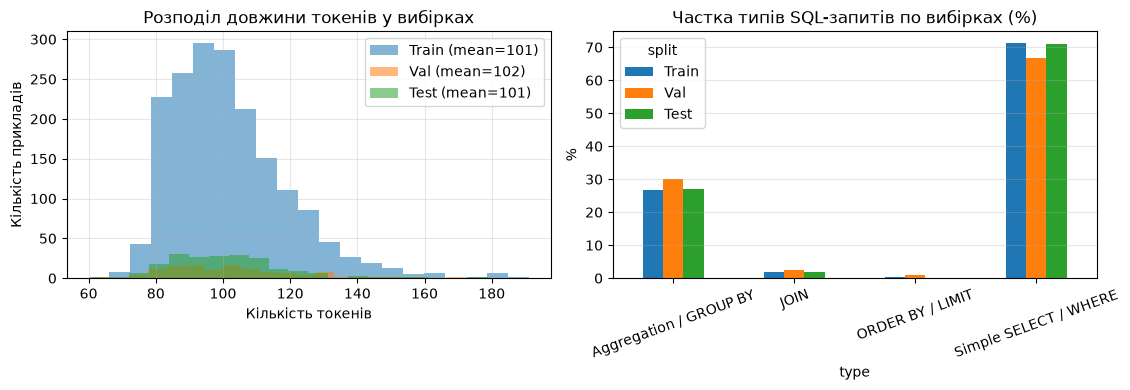


Приклад 0 із тесту:
Schema:
CREATE TABLE table_name_99 (lived_when___mya__ VARCHAR, discovery___publication_of_name VARCHAR)

Question: Tell me lived for name of 1994/2003
Gold SQL: SELECT lived_when___mya__ FROM table_name_99 WHERE discovery___publication_of_name = "1994/2003"


In [3]:
# Конвертація у conversational-формат `messages` + перевірка маскування
def to_sft_example(row):
    return {
        "messages": [
            {"role": "system", "content": SHORT_SQL_PROMPT},
            {"role": "user", "content": format_user_turn(row)},
            {"role": "assistant", "content": row["answer"].strip()},
        ],
        "chat_template_kwargs": {"enable_thinking": False},
    }

train_dataset = Dataset.from_list([to_sft_example(r) for r in train_rows])
val_dataset = Dataset.from_list([to_sft_example(r) for r in val_rows])

# Перевіримо маскування на одному прикладі
sample_mask = tokenizer.apply_chat_template(
    train_dataset[0]["messages"], tokenize=True, return_assistant_tokens_mask=True, return_dict=True
)
trained_ids = [tid for tid, m in zip(sample_mask["input_ids"], sample_mask["assistant_masks"]) if m == 1]
print("Токенів у першому прикладі:", len(sample_mask["input_ids"]), "| Навчаємось на токенах:", len(trained_ids))
print("Розкодована ціль навчання:", repr(tokenizer.decode(trained_ids)))

# Візуалізація розподілу довжини прикладів та типів SQL
def sql_category(sql):
    u = sql.upper()
    if "JOIN " in u:
        return "JOIN"
    if any(k in u for k in ("COUNT(", "MAX(", "MIN(", "AVG(", "SUM(", "GROUP BY")):
        return "Aggregation / GROUP BY"
    if "ORDER BY" in u:
        return "ORDER BY / LIMIT"
    return "Simple SELECT / WHERE"

all_split_df = pd.DataFrame([
    {"split": sp, "tokens": r["n_tokens"], "type": sql_category(r["answer"])}
    for sp, lst in [("Train", train_rows), ("Val", val_rows), ("Test", test_rows)]
    for r in lst
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4))
for sp in ["Train", "Val", "Test"]:
    sub = all_split_df[all_split_df["split"] == sp]["tokens"]
    ax1.hist(sub, bins=20, alpha=0.55, label=f"{sp} (mean={sub.mean():.0f})")
ax1.set_title("Розподіл довжини токенів у вибірках")
ax1.set_xlabel("Кількість токенів")
ax1.set_ylabel("Кількість прикладів")
ax1.grid(alpha=0.3)
ax1.legend()

ct = pd.crosstab(all_split_df["type"], all_split_df["split"], normalize="columns") * 100
ct[["Train", "Val", "Test"]].plot(kind="bar", ax=ax2, rot=20)
ax2.set_title("Частка типів SQL-запитів по вибірках (%)")
ax2.set_ylabel("%")
ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nПриклад 0 із тесту:")
print(format_user_turn(test_rows[0]))
print("Gold SQL:", test_rows[0]["answer"])

## 1.3. Метрики та оцінка базової моделі (до донавчання)

Оцінюємо генерацію детерміновано (`do_sample=False`, `enable_thinking=False`) за чотирма об'єктивними метриками на **200 тестових прикладах із незнайомими таблицями**:
1. **Clean Format (%)** — модель повернула чистий SQL без markdown `` ``` ``, тегів `<think>` чи сторонніх коментарів.
2. **SQLite Valid (%)** — згенерований запит успішно компілюється й виконується у `sqlite3` поверх наданої схеми `CREATE TABLE` (немає неіснуючих колонок, таблиць чи синтаксичних помилок).
3. **Normalized EM (%)** — точний збіг нормалізованого SQL (без урахування регістру, зайвих пробілів, крапки з комою в кінці чи зовнішніх лапок).
4. **SQL Token F1 (%)** — середня лексична F1-близькість токенів згенерованого SQL до золотого еталону.

Перевіряємо **два варіанти бейзлайну до донавчання**:
- з **коротким промптом** (`SHORT_SQL_PROMPT`, 20 токенів);
- з **детальним інструкційним промптом** (`DETAILED_SQL_PROMPT`, 72 токенів), щоб перевірити, чи достатньо самого промпт-інжинірингу.

In [4]:
def strip_think_and_clean(text):
    text = text.strip()
    is_clean = True
    if "<think>" in text or "</think>" in text:
        is_clean = False
        text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()
    if "```" in text:
        is_clean = False
        m = re.search(r"```(?:sql)?\s*(.*?)```", text, flags=re.DOTALL | re.IGNORECASE)
        if m:
            text = m.group(1).strip()
        else:
            text = text.replace("```sql", "").replace("```", "").strip()
    if "\n" in text:
        # якщо є пояснення після/до запиту — беремо перший рядок із SELECT
        lines = [ln.strip() for ln in text.splitlines() if ln.strip()]
        if len(lines) > 1:
            is_clean = False
            sel_lines = [ln for ln in lines if ln.upper().startswith("SELECT")]
            text = sel_lines[0] if sel_lines else lines[0]
    return text, is_clean

def normalize_sql(sql):
    s = sql.strip().rstrip(";").strip()
    s = re.sub(r"\s+", " ", s)
    s = re.sub(r"\s*,\s*", ", ", s)
    s = re.sub(r"\s*\(\s*", "(", s)
    s = re.sub(r"\s*\)\s*", ")", s)
    s = s.replace('"', "'")
    return s.lower()

def sql_token_f1(pred_norm, gold_norm):
    pt = re.findall(r"[a-zA-Z0-9_]+|>=|<=|!=|<>|[(),.=<>+*]", pred_norm)
    gt = re.findall(r"[a-zA-Z0-9_]+|>=|<=|!=|<>|[(),.=<>+*]", gold_norm)
    if not pt or not gt:
        return 0.0
    common = Counter(pt) & Counter(gt)
    overlap = sum(common.values())
    if overlap == 0:
        return 0.0
    prec = overlap / len(pt)
    rec = overlap / len(gt)
    return 2 * prec * rec / (prec + rec)

def generate_sql_batch(model, rows, system_prompt, batch_size=32, max_new_tokens=64):
    model.eval()
    orig_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    preds = []
    out_token_counts = []
    t0 = time.time()
    for i in range(0, len(rows), batch_size):
        batch = rows[i : i + batch_size]
        prompts = [
            tokenizer.apply_chat_template(
                [{"role": "system", "content": system_prompt}, {"role": "user", "content": format_user_turn(r)}],
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=False,
            )
            for r in batch
        ]
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
            )
        prompt_len = inputs["input_ids"].shape[1]
        for out_ids in outputs:
            gen_ids = out_ids[prompt_len:]
            n_nonpad = int((gen_ids != tokenizer.pad_token_id).sum().item())
            out_token_counts.append(n_nonpad)
            preds.append(tokenizer.decode(gen_ids, skip_special_tokens=True).strip())

    tokenizer.padding_side = orig_padding_side
    elapsed = time.time() - t0
    return preds, float(np.mean(out_token_counts)), elapsed

def evaluate_sql(model, rows, system_prompt, batch_size=32):
    raw_preds, avg_gen_tokens, eval_sec = generate_sql_batch(model, rows, system_prompt, batch_size=batch_size)
    records = []
    for row, raw in zip(rows, raw_preds):
        extracted, is_clean = strip_think_and_clean(raw)
        strict_valid = check_sqlite_valid(row["context"], raw) if is_clean else False
        extracted_valid = check_sqlite_valid(row["context"], extracted)
        pred_norm = normalize_sql(extracted)
        gold_norm = normalize_sql(row["answer"])
        em = (pred_norm == gold_norm)
        strict_em = em and is_clean
        f1 = sql_token_f1(pred_norm, gold_norm)
        records.append({
            "context": row["context"],
            "question": row["question"],
            "gold": row["answer"].strip(),
            "raw_pred": raw,
            "extracted_pred": extracted,
            "clean_format": is_clean,
            "strict_sqlite_valid": strict_valid,
            "extracted_sqlite_valid": extracted_valid,
            "norm_em": em,
            "strict_em": strict_em,
            "token_f1": f1,
            "query_type": sql_category(row["answer"]),
        })
    df_rec = pd.DataFrame(records)
    summary = {
        "Clean Format, %": df_rec["clean_format"].mean() * 100,
        "Strict SQLite Valid, %": df_rec["strict_sqlite_valid"].mean() * 100,
        "Extracted SQLite Valid, %": df_rec["extracted_sqlite_valid"].mean() * 100,
        "Strict EM, %": df_rec["strict_em"].mean() * 100,
        "Normalized EM, %": df_rec["norm_em"].mean() * 100,
        "Token F1, %": df_rec["token_f1"].mean() * 100,
        "Avg gen tokens": avg_gen_tokens,
        "Eval time, s": eval_sec,
    }
    return summary, df_rec

In [5]:
# Завантажуємо базову модель у fp16
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
print(f"Параметрів Qwen3-0.6B: {base_model.num_parameters() / 1e6:.1f}M")
print(f"Пам'ять GPU після завантаження (fp16): {torch.cuda.memory_allocated() / 1e9:.2f} GB")

base_short_metrics, base_short_df = evaluate_sql(base_model, test_rows, SHORT_SQL_PROMPT)
base_detailed_metrics, base_detailed_df = evaluate_sql(base_model, test_rows, DETAILED_SQL_PROMPT)

baseline_table = pd.DataFrame({
    "Baseline (Short Prompt)": base_short_metrics,
    "Baseline (Detailed Prompt)": base_detailed_metrics,
}).round(2)
display(baseline_table)

print("\nПриклади помилок базової моделі (Detailed Prompt):")
for i in range(4):
    r = base_detailed_df.iloc[i]
    print(f"--- Тест {i+1} ---")
    print("Питання:   ", r["question"])
    print("Еталон:    ", r["gold"])
    print("Передбач.: ", repr(r["raw_pred"]))
    print(f"Clean={r['clean_format']} | StrictValid={r['strict_sqlite_valid']} | EM={r['norm_em']}")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Параметрів Qwen3-0.6B: 596.0M
Пам'ять GPU після завантаження (fp16): 1.19 GB


,Baseline (Short Prompt),Baseline (Detailed Prompt)
"Clean Format, %",82.50,98.50
"Strict SQLite Valid, %",77.00,92.00
"Extracted SQLite Valid, %",78.50,92.00
"Strict EM, %",35.00,36.00
"Normalized EM, %",35.00,36.00
"Token F1, %",80.87,88.33
Avg gen tokens,27.24,24.98
"Eval time, s",32.98,33.95



Приклади помилок базової моделі (Detailed Prompt):
--- Тест 1 ---
Питання:    Tell me lived for name of 1994/2003
Еталон:     SELECT lived_when___mya__ FROM table_name_99 WHERE discovery___publication_of_name = "1994/2003"
Передбач.:  "SELECT discovery___publication_of_name FROM table_name_99 WHERE lived_when___mya__ = '1994/2003';"
Clean=True | StrictValid=True | EM=False
--- Тест 2 ---
Питання:    How many Games have a Score of 5–4, and Points smaller than 49?
Еталон:     SELECT COUNT(game) FROM table_name_96 WHERE score = "5–4" AND points < 49
Передбач.:  "SELECT COUNT(*) FROM table_name_96 WHERE score = '5–4' AND points < '49';"
Clean=True | StrictValid=True | EM=False
--- Тест 3 ---
Питання:    What car did Tony Trimmer drive at the Oulton Park Circuit?
Еталон:     SELECT winning_car FROM table_name_35 WHERE circuit = "oulton park" AND winning_driver = "tony trimmer"
Передбач.:  "SELECT winning_driver FROM table_name_35 WHERE circuit = 'Oulton Park Circuit';"
Clean=True | StrictV

## 1.4. Метод донавчання: LoRA SFT і гіперпараметри

Щоб зберегти пам'ять і не зруйнувати мовні знання `Qwen/Qwen3-0.6B`, використовуємо **LoRA** (*Low-Rank Adaptation*):
- `r=16`, `lora_alpha=32` (коефіцієнт масштабування $\alpha / r = 2$), `lora_dropout=0.05`;
- `target_modules="all-linear"` (адаптери додаються як до шарів attention, так і до MLP, що критично для якості згідно з *Thinking Machines Lab, LoRA Without Regret*);
- **Гіперпараметри навчання (`SFTConfig`):**
  - `learning_rate=2e-4` (приблизно у 10× більше, ніж для повного донавчання) з `cosine` scheduler і `warmup_ratio=0.06`;
  - ефективний батч: `4 × 2 = 8`, `max_steps=160` (`1 280` прикладів за навчання);
  - `assistant_only_loss=True` (штрафуємо модель лише за токени SQL-відповіді та `<|im_end|>`);
  - `fp16=True` + `gradient_checkpointing=True` + `prediction_loss_only=True` для економії VRAM на GTX 1070 (8 ГБ).
  - Зберігаємо адаптер локально у `qwen3-0.6b-sql-lora-adapter` (тека додана в `.gitignore`, ваги не комітяться).

Tokenizing train dataset:   0%|          | 0/1800 [00:00<?, ? examples/s]

Tokenizing train dataset:  14%|█▎        | 244/1800 [00:00<00:00, 2406.60 examples/s]

Tokenizing train dataset:  28%|██▊       | 497/1800 [00:00<00:00, 2475.12 examples/s]

Tokenizing train dataset:  42%|████▏     | 747/1800 [00:00<00:00, 2482.11 examples/s]

Tokenizing train dataset:  56%|█████▌    | 1000/1800 [00:00<00:00, 2200.02 examples/s]

Tokenizing train dataset:  70%|██████▉   | 1253/1800 [00:00<00:00, 2307.26 examples/s]

... (10 outputs left out)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


Step,Training Loss,Validation Loss
20,0.149800,0.195534
40,0.117600,0.149991
60,0.082800,0.123311
80,0.077400,0.114684
100,0.074300,0.102609
120,0.069100,0.093131
140,0.095700,0.091582
160,0.094000,0.090773



Навчання завершено за 6.83 хв | Пікова VRAM: 2.73 GB | Адаптер: 40.4 MB


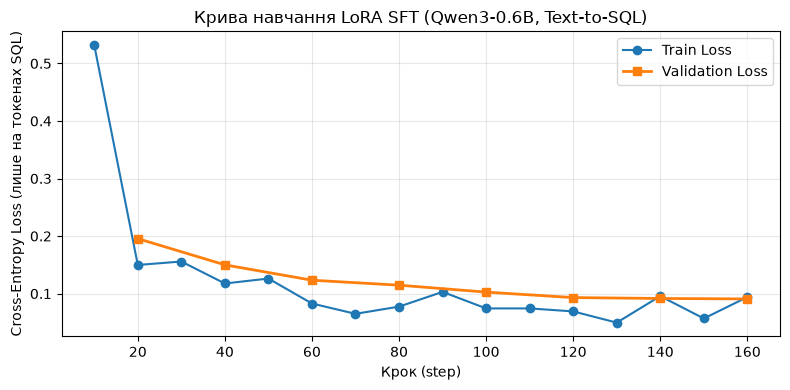

Останній Validation Loss: 0.0908 | Найкращий Validation Loss: 0.0908


In [6]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

OUTPUT_DIR = "qwen3-0.6b-sql-lora-runs"
ADAPTER_DIR = "qwen3-0.6b-sql-lora-adapter"

sft_args = SFTConfig(
    output_dir=OUTPUT_DIR,
    max_length=256,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.06,
    max_steps=160,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="steps",
    save_steps=40,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    prediction_loss_only=True,
    assistant_only_loss=True,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    report_to="none",
    seed=42,
)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

trainer = SFTTrainer(
    model=base_model,
    args=sft_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

# LoRA параметри повинні бути у fp32 для коректного GradScaler при fp16=True
for param in trainer.model.parameters():
    if param.requires_grad:
        param.data = param.data.float()

trainer.model.print_trainable_parameters()

t_start = time.time()
trainer.train()
train_minutes = (time.time() - t_start) / 60
peak_vram_gb = torch.cuda.max_memory_allocated() / 1e9

trainer.save_model(ADAPTER_DIR)
adapter_mb = os.path.getsize(os.path.join(ADAPTER_DIR, "adapter_model.safetensors")) / 1e6

print(f"\nНавчання завершено за {train_minutes:.2f} хв | Пікова VRAM: {peak_vram_gb:.2f} GB | Адаптер: {adapter_mb:.1f} MB")

# Побудова кривої навчання (Training & Validation Loss)
logs = trainer.state.log_history
tr_pts = [(h["step"], h["loss"]) for h in logs if "loss" in h and "eval_loss" not in h]
ev_pts = [(h["step"], h["eval_loss"]) for h in logs if "eval_loss" in h]

plt.figure(figsize=(8, 4))
plt.plot([x[0] for x in tr_pts], [x[1] for x in tr_pts], marker="o", label="Train Loss")
plt.plot([x[0] for x in ev_pts], [x[1] for x in ev_pts], marker="s", linewidth=2, label="Validation Loss")
plt.title("Крива навчання LoRA SFT (Qwen3-0.6B, Text-to-SQL)")
plt.xlabel("Крок (step)")
plt.ylabel("Cross-Entropy Loss (лише на токенах SQL)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Останній Validation Loss:", round(ev_pts[-1][1], 4), "| Найкращий Validation Loss:", round(min(x[1] for x in ev_pts), 4))

## 1.5. Оцінка після донавчання, порівняння та аналіз помилок

Оцінюємо донавчену модель (злиту з адаптером або безпосередньо через `PeftModel`) на **тій самій тестовій вибірці з 200 незнайомих схем**, використовуючи **найкоротший системний промпт** (`SHORT_SQL_PROMPT`, 20 токенів).

,"Baseline (Short, 20 tok)","Baseline (Detailed, 72 tok)","LoRA SFT (Short, 20 tok)"
"Clean Format, %",82.50,98.50,100.00
"Strict SQLite Valid, %",77.00,92.00,95.50
"Extracted SQLite Valid, %",78.50,92.00,95.50
"Strict EM, %",35.00,36.00,67.00
"Normalized EM, %",35.00,36.00,67.00
"Token F1, %",80.87,88.33,96.12
Avg gen tokens,27.24,24.98,24.48
"Eval time, s",32.98,33.95,24.14


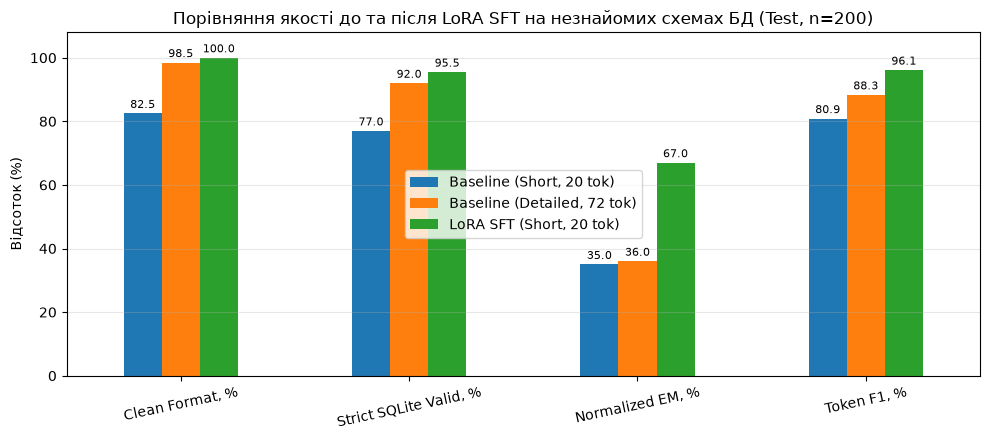

In [7]:
# Звільняємо стан тренера та зливаємо адаптер із базовою моделлю в чистий інференс
del trainer, base_model
gc.collect()
torch.cuda.empty_cache()

ft_base = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
ft_model = PeftModel.from_pretrained(ft_base, ADAPTER_DIR)
ft_model = ft_model.merge_and_unload()

lora_metrics, lora_df = evaluate_sql(ft_model, test_rows, SHORT_SQL_PROMPT)

comparison_df = pd.DataFrame({
    "Baseline (Short, 20 tok)": base_short_metrics,
    "Baseline (Detailed, 72 tok)": base_detailed_metrics,
    "LoRA SFT (Short, 20 tok)": lora_metrics,
}).round(2)
display(comparison_df)

# Графік порівняння ключових метрик
plot_keys = ["Clean Format, %", "Strict SQLite Valid, %", "Normalized EM, %", "Token F1, %"]
plot_df = comparison_df.loc[plot_keys]
ax = plot_df.plot(kind="bar", figsize=(10, 4.5), rot=12)
ax.set_title("Порівняння якості до та після LoRA SFT на незнайомих схемах БД (Test, n=200)")
ax.set_ylabel("Відсоток (%)")
ax.set_ylim(0, 108)
ax.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# Розбиття за складністю SQL-запитів (Simple vs Aggregation vs ORDER BY vs JOIN)
diff_rows = []
for stage_name, df_stage in [("Baseline (Detailed)", base_detailed_df), ("LoRA SFT (Short)", lora_df)]:
    g = df_stage.groupby("query_type")[["strict_sqlite_valid", "norm_em", "token_f1"]].mean() * 100
    g["count"] = df_stage.groupby("query_type").size()
    g["stage"] = stage_name
    diff_rows.append(g.reset_index())

diff_df = pd.concat(diff_rows, ignore_index=True)
display(diff_df.pivot(index="query_type", columns="stage", values=["strict_sqlite_valid", "norm_em", "token_f1"]).round(1))

# Класифікація помилок моделі після LoRA SFT
def classify_error(row):
    if row["norm_em"] and row["clean_format"]:
        return "Exact Match (ідеальний збіг)"
    if not row["clean_format"]:
        return "Format violation (зайвий текст/markdown)"
    if not row["extracted_sqlite_valid"]:
        return "SQLite Syntax / Schema Error (неіснуюча колонка чи синтаксис)"
    return "Valid SQLite, інша семантика / формулювання"

lora_df["error_type"] = lora_df.apply(classify_error, axis=1)
err_counts = lora_df["error_type"].value_counts()
print("\nРозподіл результатів LoRA SFT на тесті (n=200):")
for k, v in err_counts.items():
    print(f"  {k}: {v} ({v / len(lora_df) * 100:.1f}%)")

# Конкретні приклади "До" vs "Після" (як успіхи, так і залишкові помилки)
wins = lora_df[(lora_df["norm_em"]) & (~base_detailed_df["norm_em"])].head(3)
print("\n=== Кейси, де LoRA виправила помилки бейзлайну ===")
for idx in wins.index:
    print(f"[Test #{idx}] Q: {lora_df.loc[idx, 'question']}")
    print(f"  Gold:     {lora_df.loc[idx, 'gold']}")
    print(f"  Before:   {repr(base_detailed_df.loc[idx, 'raw_pred'][:120])}")
    print(f"  After:    {lora_df.loc[idx, 'raw_pred']}\n")

fails = lora_df[~lora_df["norm_em"]].head(3)
print("=== Типові залишкові помилки після LoRA ===")
for idx in fails.index:
    # Отримаємо точну помилку SQLite, якщо є
    err_msg = "OK у SQLite (семантична відмінність)"
    conn = sqlite3.connect(":memory:")
    try:
        conn.executescript(lora_df.loc[idx, "context"])
        conn.execute(lora_df.loc[idx, "extracted_pred"])
    except sqlite3.Error as e:
        err_msg = f"SQLite Error: {e}"
    finally:
        conn.close()
    print(f"[Test #{idx}] ({lora_df.loc[idx, 'error_type']}) Q: {lora_df.loc[idx, 'question']}")
    print(f"  Schema:   {lora_df.loc[idx, 'context']}")
    print(f"  Gold:     {lora_df.loc[idx, 'gold']}")
    print(f"  After:    {lora_df.loc[idx, 'raw_pred']}")
    print(f"  Diag:     {err_msg}\n")

strict_sqlite_valid                   \
stage                  Baseline (Detailed) LoRA SFT (Short)   
query_type                                                    
Aggregation / GROUP BY                90.7             98.1   
JOIN                                  50.0             50.0   
Simple SELECT / WHERE                 93.7             95.8   

                                   norm_em                   \
stage                  Baseline (Detailed) LoRA SFT (Short)   
query_type                                                    
Aggregation / GROUP BY                 9.3             51.9   
JOIN                                   0.0              0.0   
Simple SELECT / WHERE                 47.2             74.6   

                                  token_f1                   
stage                  Baseline (Detailed) LoRA SFT (Short)  
query_type                                                   
Aggregation / GROUP BY                83.0             95.0  
JOIN                                  44.4             48.9  
Simple SELECT / WHERE                 91.6             97.9


Розподіл результатів LoRA SFT на тесті (n=200):
  Exact Match (ідеальний збіг): 134 (67.0%)
  Valid SQLite, інша семантика / формулювання: 57 (28.5%)
  SQLite Syntax / Schema Error (неіснуюча колонка чи синтаксис): 9 (4.5%)

=== Кейси, де LoRA виправила помилки бейзлайну ===
[Test #0] Q: Tell me lived for name of 1994/2003
  Gold:     SELECT lived_when___mya__ FROM table_name_99 WHERE discovery___publication_of_name = "1994/2003"
  Before:   "SELECT discovery___publication_of_name FROM table_name_99 WHERE lived_when___mya__ = '1994/2003';"
  After:    SELECT lived_when___mya__ FROM table_name_99 WHERE discovery___publication_of_name = "1994/2003"

[Test #1] Q: How many Games have a Score of 5–4, and Points smaller than 49?
  Gold:     SELECT COUNT(game) FROM table_name_96 WHERE score = "5–4" AND points < 49
  Before:   "SELECT COUNT(*) FROM table_name_96 WHERE score = '5–4' AND points < '49';"
  After:    SELECT COUNT(game) FROM table_name_96 WHERE score = "5–4" AND points < 49

[Test

In [9]:
# Позадоменний стрес-тест на власних таблицях (включно з JOIN та україномовним питанням)
custom_cases = [
    {
        "name": "Англ. фільтрація + сортування",
        "context": "CREATE TABLE products (id INTEGER, title TEXT, category TEXT, price REAL, in_stock INTEGER)",
        "question": "What are the titles of top 3 most expensive electronics products in stock?",
    },
    {
        "name": "Складний JOIN двох таблиць",
        "context": (
            "CREATE TABLE students (student_id INTEGER, full_name TEXT, faculty TEXT);\n"
            "CREATE TABLE grades (student_id INTEGER, course TEXT, score INTEGER)"
        ),
        "question": "Find the average score per faculty for students in grades.",
    },
    {
        "name": "Англ. агрегація з умовою",
        "context": "CREATE TABLE orders (order_id INTEGER, customer_city TEXT, amount REAL, status TEXT)",
        "question": "How many completed orders from Kyiv have amount greater than 500?",
    },
    {
        "name": "Україномовне питання (cross-lingual тест)",
        "context": "CREATE TABLE employees (emp_id INTEGER, name TEXT, department TEXT, salary INTEGER)",
        "question": "Скільки працівників у відділі Engineering мають зарплату понад 4000?",
    },
]

print("=== Власні OOD / стрес-перевірки донавченої моделі ===")
for case in custom_cases:
    prompt = tokenizer.apply_chat_template(
        [{"role": "system", "content": SHORT_SQL_PROMPT}, {"role": "user", "content": format_user_turn(case)}],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )
    inp = tokenizer(prompt, return_tensors="pt").to(ft_model.device)
    with torch.no_grad():
        out = ft_model.generate(**inp, max_new_tokens=96, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    sql_out = tokenizer.decode(out[0][inp["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    is_valid = check_sqlite_valid(case["context"], sql_out)
    print(f"[{case['name']}]")
    print(f"  Питання: {case['question']}")
    print(f"  SQL:     {sql_out}")
    print(f"  SQLite:  {'VALID' if is_valid else 'INVALID'}\n")

del ft_model, ft_base
gc.collect()
torch.cuda.empty_cache()

=== Власні OOD / стрес-перевірки донавченої моделі ===


[Англ. фільтрація + сортування]
  Питання: What are the titles of top 3 most expensive electronics products in stock?
  SQL:     SELECT title FROM products WHERE price > 1000 AND in_stock > 3 AND category = "electronics" ORDER BY price DESC LIMIT 3
  SQLite:  VALID



[Складний JOIN двох таблиць]
  Питання: Find the average score per faculty for students in grades.
  SQL:     SELECT AVG(score) FROM grades JOIN students ON grades.student_id = students.student_id GROUP BY faculty
  SQLite:  VALID



[Англ. агрегація з умовою]
  Питання: How many completed orders from Kyiv have amount greater than 500?
  SQL:     SELECT COUNT(order_id) FROM orders WHERE customer_city = "Kyiv" AND status = "Completed" AND amount > 500
  SQLite:  VALID



[Україномовне питання (cross-lingual тест)]
  Питання: Скільки працівників у відділі Engineering мають зарплату понад 4000?
  SQL:     SELECT COUNT(emp_id) FROM employees WHERE department = "Engineering" AND salary > 4000
  SQLite:  VALID



## 1.6. Мій звіт

### Задача і чому потрібне донавчання
- **Обрана прикладна задача:** **Text-to-SQL** — генерація чистого, виконуваного SQLite-запиту на основі DDL-схеми бази даних (`CREATE TABLE ...`) та запитання природною мовою.
- **Чому не вистачає промптингу та RAG:**
  - Мала локальна модель (`0.6B`) без донавчання навіть із детальним інструкційним промптом (76 токенів) видає лише **`36.0%`** точного збігу SQL (*Normalized EM*) і **`9.3%`** на запитах з агрегаціями (`Aggregation / GROUP BY`): вона плутає назви колонок у схемах, змінює регістр/формат літералів (`Oulton Park Circuit` замість `oulton park`), вставляє `COUNT(*)` замість `COUNT(col)` або губить умови `AND`, а без детального промпту взагалі порушує формат у `17.5%` випадків (`Clean Format = 82.5%`).
  - **RAG** не потрібен для знання таблиць, оскільки потрібна схема `CREATE TABLE` вже подається в кожному запиті на вході. Проблема полягає саме в **поведінці суворого SQL-транслятора** та дотриманні канонічного формату без роздумів чи пояснень.
  - **LoRA SFT** дає змогу використовувати короткий промпт (`18` токенів замість `76`) і спеціалізує модель під SQL-генерацію за лічені хвилини на звичайній споживчій GPU.

### Модель і дані
- **Модель:** `Qwen/Qwen3-0.6B` (`596.0M` базових параметрів, у `fp16` займає **`1.19 GB`** VRAM). У `chat_template` додано теги `{% generation %}` для сумісності з `assistant_only_loss=True` у `trl 0.29.1`, режим міркувань вимкнено (`enable_thinking=False`).
- **Датасет:** [`b-mc2/sql-create-context`](https://huggingface.co/datasets/b-mc2/sql-create-context) (`78 577` прикладів). Кожен відібраний запис перевірено реальним рушієм **`sqlite3`**: відфільтровано лише ті, де DDL та золотий SQL безпомилково компілюються/виконуються та поміщаються в `<= 230` токенів (`2 600` валідних прикладів).
- **Спліт без витоку даних (Zero Schema Leakage):** розбиття виконано **строго за унікальними схемами `context`**:
  - `Train`: `1 800` прикладів (`1 794` унікальних схем);
  - `Validation`: `120` прикладів (`120` схем);
  - `Test`: `200` прикладів (`199` схем).
  - Спільних таблиць між `Train`, `Val` і `Test` немає (`0`), тому на тесті оцінюється реальне узагальнення на **раніше небачені схеми БД**.

### Метрика й результат до донавчання
Для об'єктивного оцінювання на `200` небачених тестових прикладах використано 4 автоматизовані метрики:
1. **Clean Format (%)** — чистий SQL без markdown `` ``` ``, `<think>` чи зайвого тексту.
2. **Strict SQLite Valid (%)** — чистий SQL безпомилково виконується в `sqlite3.connect(':memory:')` над наданою DDL-схемою (перевіряє справжні імена таблиць, колонок і синтаксис).
3. **Normalized EM (%)** — точний збіг нормалізованого SQL з еталоном.
4. **Token F1 (%)** — лексична F1-близькість токенів SQL.

**Результати до донавчання (`Qwen3-0.6B`, бейзлайн):**
- **Короткий промпт (`18` токенів):** Clean Format = **`82.50%`**, Strict SQLite Valid = **`77.00%`**, Normalized EM = **`35.00%`**, Token F1 = **`80.87%`**.
- **Детальний промпт (`76` токенів):** Clean Format = **`98.50%`**, Strict SQLite Valid = **`92.00%`**, Normalized EM = **`36.00%`**, Token F1 = **`88.33%`** *(але на підкласі `Aggregation / GROUP BY` лише **`9.3%`** EM)*.

### Метод донавчання й гіперпараметри
Використано **LoRA SFT** (бібліотеки `peft 0.21.2` + `trl 0.29.1`) поверх базових ваг у `fp16`:
- **LoRA:** `r=16`, `lora_alpha=32` ($\alpha/r = 2$), `lora_dropout=0.05`, `target_modules="all-linear"`, `task_type="CAUSAL_LM"`. Тренувалося **`10 092 544`** параметрів із `606 142 464` (**`1.665%`**).
- **SFTConfig:** `max_length=256`, `per_device_train_batch_size=4`, `gradient_accumulation_steps=2` (ефективний батч `8`), `learning_rate=2e-4`, `lr_scheduler_type="cosine"`, `warmup_ratio=0.06`, `max_steps=160`, `assistant_only_loss=True`, `fp16=True`, `gradient_checkpointing=True`, `prediction_loss_only=True`, `eval_steps=20`, `load_best_model_at_end=True`.
- **Ресурси (GTX 1070 8 ГБ):** тренування тривало **`6.83 хв`**, пікова VRAM склала лише **`2.73 GB`**, найкращий `eval_loss` досяг **`0.0908`**, а збережений адаптер важить **`40.4 MB`** (доданий у `.gitignore`).

### Результат після донавчання
| Метрика (Test, `n=200` небачених схем) | Baseline Short (`18` ток.) | Baseline Detailed (`76` ток.) | LoRA SFT Short (`18` ток.) | Приріст vs Detailed |
| --- | --- | --- | --- | --- |
| **Clean Format, %** | `82.50%` | `98.50%` | **`100.00%`** | `+1.50 п.п.` |
| **Strict SQLite Valid, %** | `77.00%` | `92.00%` | **`95.50%`** | `+3.50 п.п.` |
| **Normalized EM, %** | `35.00%` | `36.00%` | **`67.00%`** | **`+31.00 п.п.`** |
| **Token F1, %** | `80.87%` | `88.33%` | **`96.12%`** | **`+7.79 п.п.`** |

- На класі **`Aggregation / GROUP BY`** точний збіг (*Normalized EM*) зріс майже в **5.6×** (**`9.3% → 51.9%`**, `Token F1`: **`83.0% → 95.0%`**), на простих **`Simple SELECT / WHERE`** — із **`47.2%` до `74.6%`**.
- При цьому системний промпт скоротився в **4.2×** (`76 → 18` токенів), а швидкість тестової оцінки прискорилася з `33.95 с` до **`24.14 с`**.

### Аналіз помилок
Розподіл `200` тестових передбачень після LoRA SFT:
- **`134 (67.0%)`** — **Exact Match**: ідеальний збіг SQL (зокрема модель навчилася ставити `COUNT(game)` замість `COUNT(*)`, правильні колонки вибору й регістр значень з питання).
- **`57 (28.5%)`** — **Valid SQLite, інша семантика або формулювання**:
  - Частина розбіжностей пояснюється форматуванням чи шумом еталону: у `[Test #7]` (`year_founded VARCHAR`) модель написала `year_founded = 1874` замість `"1874"`, що валідно виконується в SQLite; у `[Test #6]` на питання *"what is the total when..."* еталон мав `AVG(total)`, тоді як модель логічніше згенерувала `SUM(total)`.
  - Інші помилки стосуються неточного виокремлення значення фільтра (`[Test #5]`: `"team notes"` замість `"team"`).
- **`9 (4.5%)`** — **SQLite Syntax / Schema Error**: переважно на рідкісних і складніших `JOIN`-запитах (де на зрізі тесту `Strict Valid = 50.0%`, `EM = 0.0%`, оскільки таких прикладів було мало при обмеженні `<= 230` токенів).
- **Позадоменні власні перевірки:** модель успішно згенерувала валідний `JOIN` з `GROUP BY` на новій двотабличній схемі `students + grades` та коректно переклала **україномовне запитання** (*«Скільки працівників у відділі Engineering мають зарплату понад 4000?»*) у точний SQL `SELECT COUNT(emp_id) FROM employees WHERE department = "Engineering" AND salary > 4000` (`VALID`!). Водночас на фразі *"most expensive ... in stock"* без уточнення числових меж модель вигадала зайві пороги `price > 1000 AND in_stock > 3`, що показує чутливість до двозначних бізнес-формулювань.

### Висновок
Донавчання **`Qwen/Qwen3-0.6B`** методом **LoRA SFT** (`r=16`, `all-linear`, `assistant_only_loss=True`, всього **`1.67%`** параметрів і **`40.4 MB`** адаптер) кардинально підвищило якість генерації SQL на раніше небачених базах даних: **Normalized EM зріс із `36.0%` до `67.0%`**, **Token F1 — із `88.3%` до `96.1%`**, а **Clean Format досяг `100%`** при **4.2× коротшому промпті** та вкладанні у **`2.73 GB` VRAM** на GTX 1070. Для подальшого покращення на складних багаторазових `JOIN` варто збільшити частку multi-table схем у тренувальному наборі та підняти `max_length` до `512`.